+--------------------------------------------------------------------+
| Configuration for experiment     train_model_2026-11-02_18-47-39   |
+--------------------------------------------------------------------+
| Search algorithm                 BasicVariantGenerator             |
| Scheduler                        FIFOScheduler                     |
| Number of trials                 15                                |
+--------------------------------------------------------------------+

View detailed results here: /root/ray_results/train_model_2026-11-02_18-47-39
To visualize your results with TensorBoard, run: `tensorboard --logdir /tmp/ray/session_2026-11-02_18-47-23_410349_1501/artifacts/2026-11-02_18-47-39/train_model_2026-11-02_18-47-39/driver_artifacts`



(train_model pid=2745) Exception ignored in: <function WeakSet.__init__.<locals>._remove at 0x7e40b601d9e0>
(train_model pid=2745) Traceback (most recent call last):
(train_model pid=2745)   File "/usr/lib/python3.13/_weakrefset.py", line 39, in _remove
(train_model pid=2745)     def _remove(item, selfref=ref(self)):
(train_model pid=2745)   File "/usr/local/lib/python3.13/dist-packages/ray/_private/worker.py", line 1063, in sigterm_handler
(train_model pid=2745)     raise_sys_exit_with_custom_error_message(
(train_model pid=2745)   File "python/ray/_raylet.pyx", line 714, in ray._raylet.raise_sys_exit_with_custom_error_message
(train_model pid=2745) SystemExit
(train_model pid=2745) : 1


Best Hyperparameters:
{'n_estimators': 50, 'max_depth': 10, 'min_samples_split': 2, 'min_samples_leaf': 4}

Model Performance
Baseline Accuracy: 0.9561
Best Validation Accuracy: 0.9560
Optimized Test Accuracy: 0.9561


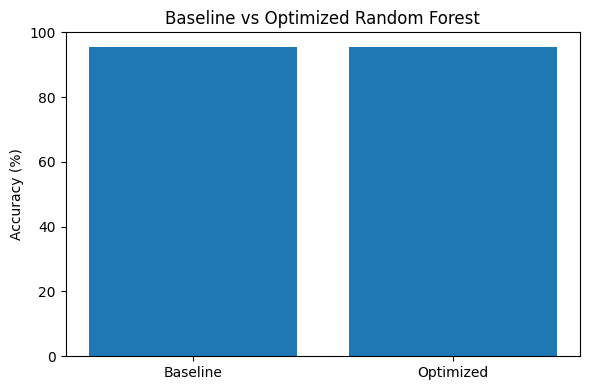

In [1]:
!pip -q install "ray[tune]"

import ray
from ray import tune
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

data = load_breast_cancer()
X = data.data
y = data.target

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=0.2, random_state=42, stratify=y_train_full)

baseline_model = RandomForestClassifier(random_state=42, n_jobs=1)
baseline_model.fit(X_train_full, y_train_full)

baseline_pred = baseline_model.predict(X_test)
baseline_accuracy = accuracy_score(y_test, baseline_pred)

def train_model(config, X_train, y_train, X_val, y_val):
    model = RandomForestClassifier(
        n_estimators=config["n_estimators"],
        max_depth=config["max_depth"],
        min_samples_split=config["min_samples_split"],
        min_samples_leaf=config["min_samples_leaf"],
        random_state=42,
        n_jobs=1)

    model.fit(X_train, y_train)
    predictions = model.predict(X_val)

    return {"val_accuracy": accuracy_score(y_val, predictions)}

search_space = {
    "n_estimators": tune.choice([50, 100, 150, 200]),
    "max_depth": tune.choice([5, 10, 15, 20, None]),
    "min_samples_split": tune.choice([2, 5, 10]),
    "min_samples_leaf": tune.choice([1, 2, 4])}

ray.init(
    num_cpus=2,
    include_dashboard=False,
    ignore_reinit_error=True,
    logging_level="ERROR")

try:
    tuner = tune.Tuner(
        tune.with_parameters(
            train_model,
            X_train=X_train,
            y_train=y_train,
            X_val=X_val,
            y_val=y_val),
        param_space=search_space,
        tune_config=tune.TuneConfig(
            metric="val_accuracy",
            mode="max",
            num_samples=15,
            max_concurrent_trials=2),
        run_config=ray.tune.RunConfig(verbose=0))

    results = tuner.fit()

    best_result = results.get_best_result(
        metric="val_accuracy",
        mode="max")

    best_config = best_result.config
    best_val_accuracy = best_result.metrics["val_accuracy"]

    best_model = RandomForestClassifier(
        **best_config,
        random_state=42,
        n_jobs=1)

    best_model.fit(X_train_full, y_train_full)
    best_pred = best_model.predict(X_test)
    best_accuracy = accuracy_score(y_test, best_pred)
    print("Best Hyperparameters:")
    print(best_config)
    print("\nModel Performance")
    print(f"Baseline Accuracy: {baseline_accuracy:.4f}")
    print(f"Best Validation Accuracy: {best_val_accuracy:.4f}")
    print(f"Optimized Test Accuracy: {best_accuracy:.4f}")
    plt.figure(figsize=(6, 4))
    plt.bar(
        ["Baseline", "Optimized"],
        [baseline_accuracy * 100, best_accuracy * 100])
    plt.ylabel("Accuracy (%)")
    plt.title("Baseline vs Optimized Random Forest")
    plt.ylim(0, 100)
    plt.tight_layout()
    plt.show()
finally:
    ray.shutdown()